# Experiment 10: Intelligent Decision Support System

**Aim:** Develop an intelligent decision-support system using rule-based reasoning, imitation learning, explanations, and ethical AI evaluation.

## Application: Student Academic Support Recommendations
This notebook builds a small educational example that recommends **Study Plan**, **Practice Questions**, or **Mentor Support**. The dataset is synthetic and for learning only; do not use it for real high-stakes decisions.

### Exercises
1. Rule-based expert system with a knowledge base and inference engine.
2. Imitation learning from example human decisions.
3. Explanation facility for recommendations.
4. Ethical AI checks across synthetic groups.
5. Compare results after changing rules and training examples.


## 1. Import Libraries
We use pandas and NumPy for data, scikit-learn for imitation learning, and Matplotlib for plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create a Synthetic Dataset
Features include attendance, assignment score, exam score, confidence, study hours, and a synthetic group label for fairness auditing. The `human_decision` label represents example decisions that the model will imitate. No real student data is used.

In [2]:
n = 500
rng = np.random.default_rng(RANDOM_STATE)

attendance = rng.integers(45, 101, n)
assignment_score = np.clip(rng.normal(68, 17, n), 0, 100).round(1)
exam_score = np.clip(rng.normal(64, 19, n), 0, 100).round(1)
confidence = rng.integers(1, 6, n)
study_hours = np.clip(rng.normal(2.2, 1.1, n), 0, 6).round(1)
support_group = rng.choice(["Group A", "Group B"], size=n)

human_decisions = []
for a, assn, exam, conf, hours in zip(attendance, assignment_score, exam_score, confidence, study_hours):
    if exam < 45 or assn < 45:
        decision = "Mentor Support"
    elif exam < 65 or assn < 60 or hours < 1.5:
        decision = "Practice Questions"
    else:
        decision = "Study Plan"
    if decision == "Study Plan" and conf <= 2 and exam < 75:
        decision = "Practice Questions"
    human_decisions.append(decision)

df = pd.DataFrame({
    "attendance": attendance,
    "assignment_score": assignment_score,
    "exam_score": exam_score,
    "confidence": confidence,
    "study_hours": study_hours,
    "support_group": support_group,
    "human_decision": human_decisions
})

display(df.head(10))
print("Dataset shape:", df.shape)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nHuman decision distribution:\n", df["human_decision"].value_counts())

,attendance,assignment_score,exam_score,confidence,study_hours,support_group,human_decision
0,49,66.4,86.6,1,2.4,Group B,Study Plan
1,88,38.1,44.6,3,1.5,Group A,Mentor Support
2,81,43.1,28.7,3,2.2,Group A,Mentor Support
3,69,100.0,65.9,2,1.5,Group B,Practice Questions
4,69,46.1,81.7,4,1.0,Group B,Practice Questions
5,93,49.4,98.2,3,1.8,Group B,Practice Questions
6,49,99.2,73.8,3,1.0,Group A,Practice Questions
7,84,100.0,56.9,3,2.6,Group A,Practice Questions
8,56,48.1,47.0,5,0.9,Group B,Practice Questions
9,50,61.7,64.2,4,3.0,Group B,Practice Questions


Dataset shape: (500, 7)

Missing values per column:
 attendance          0
assignment_score    0
exam_score          0
confidence          0
study_hours         0
support_group       0
human_decision      0
dtype: int64

Human decision distribution:
 human_decision
Practice Questions    279
Mentor Support        125
Study Plan             96
Name: count, dtype: int64


## 3. Exercise 1 — Rule-Based Expert System
An expert system contains a **knowledge base** (rules) and an **inference engine** (checks the rules). Rule order matters: the first matching rule determines the recommendation.

In [3]:
KNOWLEDGE_BASE = [
    {
        "name": "R1 — Low exam score",
        "condition": lambda x: x["exam_score"] < 45,
        "recommendation": "Mentor Support",
        "reason": "Exam score is below 45."
    },
    {
        "name": "R2 — Low assignment score",
        "condition": lambda x: x["assignment_score"] < 45,
        "recommendation": "Mentor Support",
        "reason": "Assignment score is below 45."
    },
    {
        "name": "R3 — Needs more practice",
        "condition": lambda x: x["exam_score"] < 65 or x["assignment_score"] < 60,
        "recommendation": "Practice Questions",
        "reason": "Exam score is below 65 or assignment score is below 60."
    },
    {
        "name": "R4 — Low study time",
        "condition": lambda x: x["study_hours"] < 1.5,
        "recommendation": "Practice Questions",
        "reason": "Reported study time is below 1.5 hours/day."
    },
    {
        "name": "R5 — General revision",
        "condition": lambda x: True,
        "recommendation": "Study Plan",
        "reason": "No higher-priority rule matched; use a structured revision plan."
    }
]

def expert_system(student, rules=KNOWLEDGE_BASE):
    for rule in rules:
        if rule["condition"](student):
            return {
                "recommendation": rule["recommendation"],
                "rule": rule["name"],
                "reason": rule["reason"]
            }
    return {"recommendation": "Study Plan", "rule": "Default", "reason": "No rule matched."}

example_student = {
    "attendance": 82, "assignment_score": 52, "exam_score": 58,
    "confidence": 3, "study_hours": 2.0, "support_group": "Group A"
}
expert_result = expert_system(example_student)
print("Student profile:", example_student)
print("Recommendation:", expert_result["recommendation"])
print("Rule fired:", expert_result["rule"])
print("Explanation:", expert_result["reason"])

Student profile: {'attendance': 82, 'assignment_score': 52, 'exam_score': 58, 'confidence': 3, 'study_hours': 2.0, 'support_group': 'Group A'}
Recommendation: Practice Questions
Rule fired: R3 — Needs more practice
Explanation: Exam score is below 65 or assignment score is below 60.


## 4. Apply Rules to the Dataset
Compare the rule-based recommendations with the example human decisions. Agreement is informative but does not prove that either decision is objectively correct.

In [4]:
feature_columns = ["attendance", "assignment_score", "exam_score", "confidence", "study_hours", "support_group"]
rule_results = df[feature_columns].apply(lambda row: expert_system(row.to_dict()), axis=1)
df["rule_recommendation"] = [r["recommendation"] for r in rule_results]
df["rule_fired"] = [r["rule"] for r in rule_results]
df["rule_reason"] = [r["reason"] for r in rule_results]

rule_agreement = accuracy_score(df["human_decision"], df["rule_recommendation"])
print(f"Rule system agreement with example decisions: {rule_agreement:.3f}")
display(df[feature_columns + ["human_decision", "rule_recommendation", "rule_fired"]].head(12))
display(df["rule_fired"].value_counts().rename_axis("Rule").reset_index(name="Count"))

Rule system agreement with example decisions: 0.964


,attendance,assignment_score,exam_score,confidence,study_hours,support_group,human_decision,rule_recommendation,rule_fired
0,49,66.4,86.6,1,2.4,Group B,Study Plan,Study Plan,R5 — General revision
1,88,38.1,44.6,3,1.5,Group A,Mentor Support,Mentor Support,R1 — Low exam score
2,81,43.1,28.7,3,2.2,Group A,Mentor Support,Mentor Support,R1 — Low exam score
3,69,100.0,65.9,2,1.5,Group B,Practice Questions,Study Plan,R5 — General revision
4,69,46.1,81.7,4,1.0,Group B,Practice Questions,Practice Questions,R3 — Needs more practice
5,93,49.4,98.2,3,1.8,Group B,Practice Questions,Practice Questions,R3 — Needs more practice
6,49,99.2,73.8,3,1.0,Group A,Practice Questions,Practice Questions,R4 — Low study time
7,84,100.0,56.9,3,2.6,Group A,Practice Questions,Practice Questions,R3 — Needs more practice
8,56,48.1,47.0,5,0.9,Group B,Practice Questions,Practice Questions,R3 — Needs more practice
9,50,61.7,64.2,4,3.0,Group B,Practice Questions,Practice Questions,R3 — Needs more practice


,Rule,Count
0,R3 — Needs more practice,211
1,R5 — General revision,114
2,R1 — Low exam score,81
3,R4 — Low study time,50
4,R2 — Low assignment score,44


## 5. Exercise 2 — Imitation Learning
The model learns from `human_decision` labels. A held-out test set is used to estimate performance on unseen records. The synthetic group label is excluded from model features but retained for the fairness audit.

Test accuracy: 0.984

Classification report:
                    precision    recall  f1-score   support

    Mentor Support       1.00      0.97      0.98        31
Practice Questions       0.97      1.00      0.99        70
        Study Plan       1.00      0.96      0.98        24

          accuracy                           0.98       125
         macro avg       0.99      0.98      0.98       125
      weighted avg       0.98      0.98      0.98       125



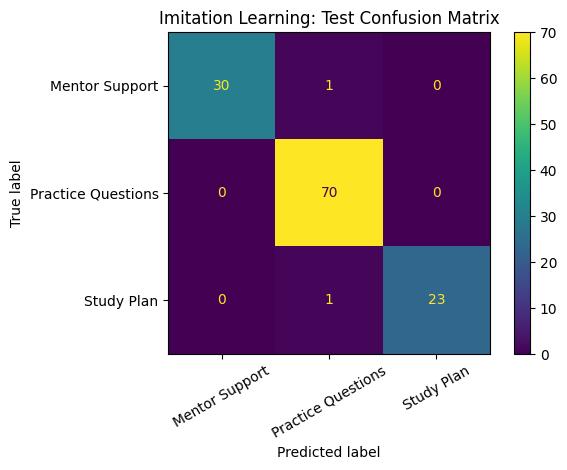

In [5]:
X = df[["attendance", "assignment_score", "exam_score", "confidence", "study_hours"]]
y = df["human_decision"]

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

imitation_model = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"))
])
imitation_model.fit(X_train, y_train)
y_pred = imitation_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=30)
plt.title("Imitation Learning: Test Confusion Matrix")
plt.tight_layout()
plt.show()

### Predict for a new example
This prediction imitates the example labels; it is not a guarantee of the best action.

In [6]:
new_student = pd.DataFrame([{
    "attendance": 76, "assignment_score": 71, "exam_score": 62,
    "confidence": 3, "study_hours": 1.8
}])
predicted_decision = imitation_model.predict(new_student)[0]
display(new_student)
print("Imitated human decision:", predicted_decision)

,attendance,assignment_score,exam_score,confidence,study_hours
0,76,71,62,3,1.8


Imitated human decision: Practice Questions


## 6. Exercise 3 — Explanation Facility
The rule-based system can provide the exact rule and reason. For the learned model, we display Random Forest feature importance. Feature importance describes overall model behavior, not a complete causal explanation for an individual prediction.

RULE-BASED EXPLANATION
Recommendation: Practice Questions
Rule: R3 — Needs more practice
Reason: Exam score is below 65 or assignment score is below 60.


,Importance
exam_score,0.511989
assignment_score,0.281480
study_hours,0.136748
attendance,0.035394
confidence,0.034389


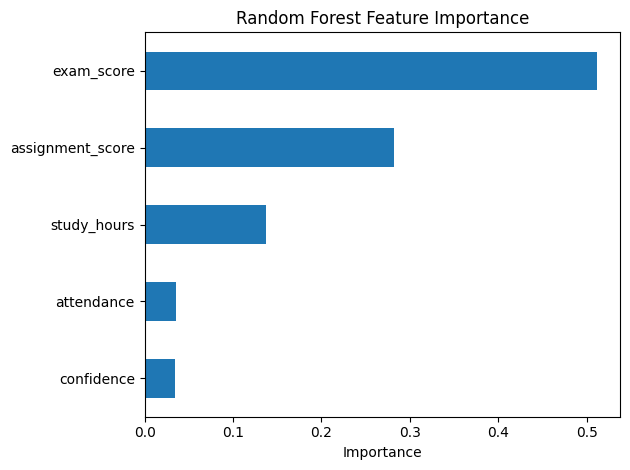

In [7]:
new_profile = {
    "attendance": 76, "assignment_score": 71, "exam_score": 62,
    "confidence": 3, "study_hours": 1.8, "support_group": "Group A"
}
rule_explanation = expert_system(new_profile)
print("RULE-BASED EXPLANATION")
print("Recommendation:", rule_explanation["recommendation"])
print("Rule:", rule_explanation["rule"])
print("Reason:", rule_explanation["reason"])

rf = imitation_model.named_steps["classifier"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)
display(importance.sort_values(ascending=False).rename("Importance").to_frame())
importance.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 7. Exercise 4 — Ethical AI: Fairness and Transparency
We compare recommendation rates and accuracy across synthetic groups. Although group membership is not a model input, other feature distributions can differ between groups.

We calculate:
- Recommendation rates within each group.
- Test accuracy by group.
- Demographic-parity difference: maximum minus minimum group recommendation rate for each action.

These are diagnostics, not proof of fairness. This synthetic dataset is not representative of real students, and no single metric captures every ethical concern.

Recommendation rates by group:


model_prediction,Study Plan,Practice Questions,Mentor Support
support_group,,,
Group A,0.125,0.625,0.25
Group B,0.246,0.525,0.23


Agreement with example decisions by group:


,Test accuracy
support_group,
Group A,1.000
Group B,0.967


Demographic-parity differences by recommendation:


,Max-min group rate difference
model_prediction,
Study Plan,0.121
Practice Questions,0.100
Mentor Support,0.020


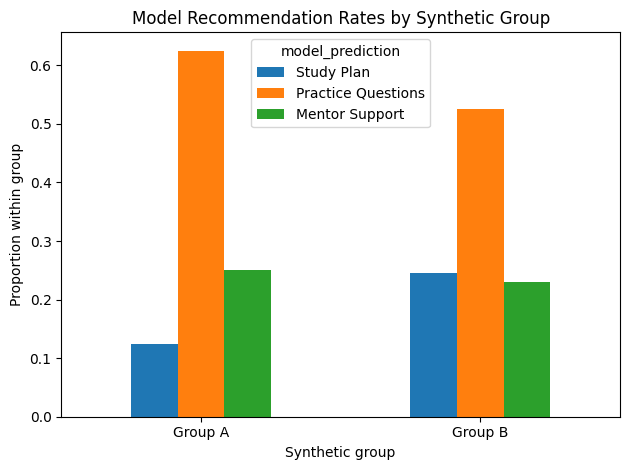

In [8]:
audit = df.loc[idx_test, ["support_group", "human_decision"]].copy()
audit["model_prediction"] = y_pred

print("Recommendation rates by group:")
recommendation_rates = pd.crosstab(audit["support_group"], audit["model_prediction"], normalize="index")
recommendation_rates = recommendation_rates.reindex(columns=["Study Plan", "Practice Questions", "Mentor Support"], fill_value=0)
display(recommendation_rates.round(3))

print("Agreement with example decisions by group:")
audit["correct"] = audit["human_decision"] == audit["model_prediction"]
display(audit.groupby("support_group")["correct"].mean().rename("Test accuracy").to_frame().round(3))

print("Demographic-parity differences by recommendation:")
parity_difference = recommendation_rates.max(axis=0) - recommendation_rates.min(axis=0)
display(parity_difference.rename("Max-min group rate difference").to_frame().round(3))

recommendation_rates.plot(kind="bar")
plt.title("Model Recommendation Rates by Synthetic Group")
plt.ylabel("Proportion within group")
plt.xlabel("Synthetic group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Ethical reflection
1. Are the features relevant, or could they act as proxies for disadvantage?
2. Would a student understand why an action was recommended?
3. Could an incorrect recommendation harm someone, and how should a human review it?
4. Are group sizes large enough for meaningful comparisons?
5. Can a student challenge or correct the data used?

Responsible use requires appropriate validation, privacy protections, transparency, and human oversight.

## 8. Exercise 5 — Compare Before and After Rule Changes
We raise the low-exam-score threshold from 45 to 55, then compare recommendations before and after the change.

Rule-based recommendations changed: 62 of 500


,Before,After
Practice Questions,261,199
Mentor Support,125,187
Study Plan,114,114


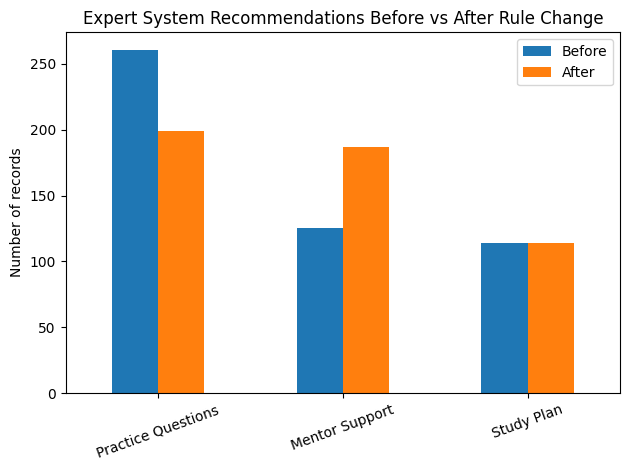

,exam_score,assignment_score,rule_before,rule_after
8,47.0,48.1,Practice Questions,Mentor Support
15,46.5,75.4,Practice Questions,Mentor Support
26,53.4,74.0,Practice Questions,Mentor Support
49,49.8,63.7,Practice Questions,Mentor Support
59,47.9,97.4,Practice Questions,Mentor Support
70,53.0,75.5,Practice Questions,Mentor Support
72,54.4,75.5,Practice Questions,Mentor Support
73,52.1,82.1,Practice Questions,Mentor Support
79,54.9,81.3,Practice Questions,Mentor Support
93,49.7,68.6,Practice Questions,Mentor Support


In [9]:
df["rule_before"] = df[feature_columns].apply(lambda row: expert_system(row.to_dict())["recommendation"], axis=1)

modified_rules = []
for rule in KNOWLEDGE_BASE:
    if rule["name"] == "R1 — Low exam score":
        modified_rules.append({
            "name": "R1* — Low exam score (updated threshold)",
            "condition": lambda x: x["exam_score"] < 55,
            "recommendation": "Mentor Support",
            "reason": "Exam score is below updated threshold 55."
        })
    else:
        modified_rules.append(rule)

df["rule_after"] = df[feature_columns].apply(
    lambda row: expert_system(row.to_dict(), rules=modified_rules)["recommendation"], axis=1
)
changed_rule_count = (df["rule_before"] != df["rule_after"]).sum()
print("Rule-based recommendations changed:", changed_rule_count, "of", len(df))
comparison_counts = pd.concat([
    df["rule_before"].value_counts().rename("Before"),
    df["rule_after"].value_counts().rename("After")
], axis=1).fillna(0).astype(int)
display(comparison_counts)
comparison_counts.plot(kind="bar")
plt.title("Expert System Recommendations Before vs After Rule Change")
plt.ylabel("Number of records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
display(df.loc[df["rule_before"] != df["rule_after"],
               ["exam_score", "assignment_score", "rule_before", "rule_after"]].head(10))

### Change training examples and retrain
We modify a small subset of training labels as a controlled experiment, retrain the model, and compare its predictions. The altered labels are illustrative, not evidence that the new decisions are better.

Training examples modified: 12
Test predictions changed after retraining: 0 of 125
Original model agreement with original test labels: 0.984
Modified model agreement with original test labels: 0.984


,Original model,Retrained model
Practice Questions,72,72
Mentor Support,30,30
Study Plan,23,23


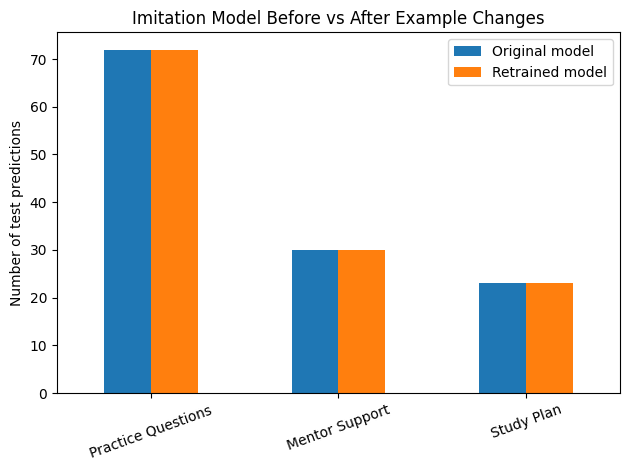

In [10]:
y_train_modified = y_train.copy()
borderline = X_train["exam_score"].between(60, 66)
indices_to_modify = y_train_modified.index[borderline][:min(12, int(borderline.sum()))]
for idx in indices_to_modify:
    y_train_modified.loc[idx] = "Practice Questions"

modified_imitation_model = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"))
])
modified_imitation_model.fit(X_train, y_train_modified)

pred_before = imitation_model.predict(X_test)
pred_after = modified_imitation_model.predict(X_test)
prediction_changes = int(np.sum(pred_before != pred_after))

print("Training examples modified:", len(indices_to_modify))
print("Test predictions changed after retraining:", prediction_changes, "of", len(y_test))
print("Original model agreement with original test labels:", round(accuracy_score(y_test, pred_before), 3))
print("Modified model agreement with original test labels:", round(accuracy_score(y_test, pred_after), 3))

learning_comparison = pd.concat([
    pd.Series(pred_before).value_counts().rename("Original model"),
    pd.Series(pred_after).value_counts().rename("Retrained model")
], axis=1).fillna(0).astype(int)
display(learning_comparison)
learning_comparison.plot(kind="bar")
plt.title("Imitation Model Before vs After Example Changes")
plt.ylabel("Number of test predictions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 9. Final Summary and Conclusion

### Implemented
- Generated a synthetic dataset with student indicators and example human decisions.
- Built a rule-based expert system with a knowledge base and inference engine.
- Trained and evaluated a Random Forest imitation-learning model.
- Explained recommendations using fired rules, reasons, and global feature importance.
- Audited recommendation rates and model agreement across synthetic groups.
- Compared outputs after modifying a rule and training examples.

### Conclusion
The experiment shows how explicit rules and learned behavior can work together in a decision-support system. Rules are inspectable; learned models can imitate patterns in examples but may be less transparent. Fairness metrics and explanations can reveal potential issues, but they do not replace careful validation and human oversight.

**Result:** The Intelligent Decision Support System was implemented and evaluated using synthetic data.
